# Dataset discovery

In [1]:
from pathlib import Path
from collections import Counter
import pandas as pd

In [4]:
DATASET_ROOT = Path(
    "/kaggle/input/datasets/mouadelbaz/"
    "tuh-normal-abnormal-dataset"
)

print("Dataset exists:", DATASET_ROOT.exists())

if DATASET_ROOT.exists():
    print("\nTop-level contents:")
    for path in sorted(DATASET_ROOT.iterdir()):
        print(path.name)

    edf_files = sorted(DATASET_ROOT.rglob("*.edf"))

    print("\nTotal EDF files:", len(edf_files))
    print("\nFirst 5 EDF files:")

    for path in edf_files[:5]:
        print(path.relative_to(DATASET_ROOT))

Dataset exists: True

Top-level contents:
TUAB

Total EDF files: 2993

First 5 EDF files:
TUAB/edf/eval/abnormal/01_tcp_ar/aaaaabdo_s003_t000.edf
TUAB/edf/eval/abnormal/01_tcp_ar/aaaaabsk_s007_t000.edf
TUAB/edf/eval/abnormal/01_tcp_ar/aaaaabuv_s002_t000.edf
TUAB/edf/eval/abnormal/01_tcp_ar/aaaaaddm_s006_t000.edf
TUAB/edf/eval/abnormal/01_tcp_ar/aaaaadeu_s002_t000.edf


# Recording labels and patient identifiers

In [5]:
records = []

for path in edf_files:
    parts = path.parts

    split = next(
        (p for p in parts if p in {"train", "eval"}),
        None
    )

    label = next(
        (p for p in parts if p in {"normal", "abnormal"}),
        None
    )

    subject_id = path.stem.split("_")[0]

    records.append({
        "filepath": str(path),
        "split": split,
        "label": label,
        "subject_id": subject_id,
    })

df = pd.DataFrame(records)

print("Recording counts:")
print(pd.crosstab(df["split"], df["label"]))

print("\nUnique subjects by split:")
print(df.groupby("split")["subject_id"].nunique())

train_subjects = set(
    df.loc[df["split"] == "train", "subject_id"]
)

eval_subjects = set(
    df.loc[df["split"] == "eval", "subject_id"]
)

print(
    "\nPatient overlap:",
    len(train_subjects & eval_subjects)
)

df.to_csv(
    "/kaggle/working/tuab_metadata_initial.csv",
    index=False
)

Recording counts:
label  abnormal  normal
split                  
eval        126     150
train      1346    1371

Unique subjects by split:
split
eval      253
train    2076
Name: subject_id, dtype: int64

Patient overlap: 0


# EEG signal metadata audit

In [6]:
import mne
from collections import Counter

metadata = []
errors = []

for i, path in enumerate(edf_files):
    try:
        raw = mne.io.read_raw_edf(
            str(path),
            preload=False,
            verbose="ERROR"
        )

        metadata.append({
            "filepath": str(path),
            "sfreq": raw.info["sfreq"],
            "n_channels": len(raw.ch_names),
            "duration_sec": raw.n_times / raw.info["sfreq"],
            "channels": tuple(raw.ch_names),
        })

        raw.close()

    except Exception as e:
        errors.append({
            "filepath": str(path),
            "error": str(e)
        })

meta_df = pd.DataFrame(metadata)

print("Successfully read:", len(meta_df))
print("Errors:", len(errors))

print("\nSampling frequencies:")
print(meta_df["sfreq"].value_counts())

print("\nNumber of channels:")
print(meta_df["n_channels"].value_counts())

print("\nRecording durations (seconds):")
print(meta_df["duration_sec"].describe())

print("\nMost common channel configurations:")
for channels, count in Counter(
    meta_df["channels"]
).most_common(5):
    print(f"\nCount: {count}")
    print(channels)

Successfully read: 2993
Errors: 0

Sampling frequencies:
sfreq
250.0    2786
256.0     189
512.0      18
Name: count, dtype: int64

Number of channels:
n_channels
36    1638
30    1012
31     139
34      72
27      62
28      29
33      26
29       8
35       7
Name: count, dtype: int64

Recording durations (seconds):
count     2993.000000
mean      1372.404945
std        594.694454
min        962.000000
25%       1206.000000
50%       1267.000000
75%       1403.000000
max      19948.000000
Name: duration_sec, dtype: float64

Most common channel configurations:

Count: 1636
('EEG FP1-REF', 'EEG FP2-REF', 'EEG F3-REF', 'EEG F4-REF', 'EEG C3-REF', 'EEG C4-REF', 'EEG P3-REF', 'EEG P4-REF', 'EEG O1-REF', 'EEG O2-REF', 'EEG F7-REF', 'EEG F8-REF', 'EEG T3-REF', 'EEG T4-REF', 'EEG T5-REF', 'EEG T6-REF', 'EEG A1-REF', 'EEG A2-REF', 'EEG FZ-REF', 'EEG CZ-REF', 'EEG PZ-REF', 'EEG ROC-REF', 'EEG LOC-REF', 'EEG EKG1-REF', 'EMG-REF', 'EEG 26-REF', 'EEG 27-REF', 'EEG 28-REF', 'EEG 29-REF', 'EEG 30-R

# **Visualization setup**

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

sns.set_theme(style="whitegrid", context="notebook")

plt.rcParams.update({
    "figure.figsize": (10, 5),
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "axes.titlesize": 14,
    "axes.labelsize": 11,
})

OUTPUT_DIR = "/kaggle/working"

# Sampling frequency distribution

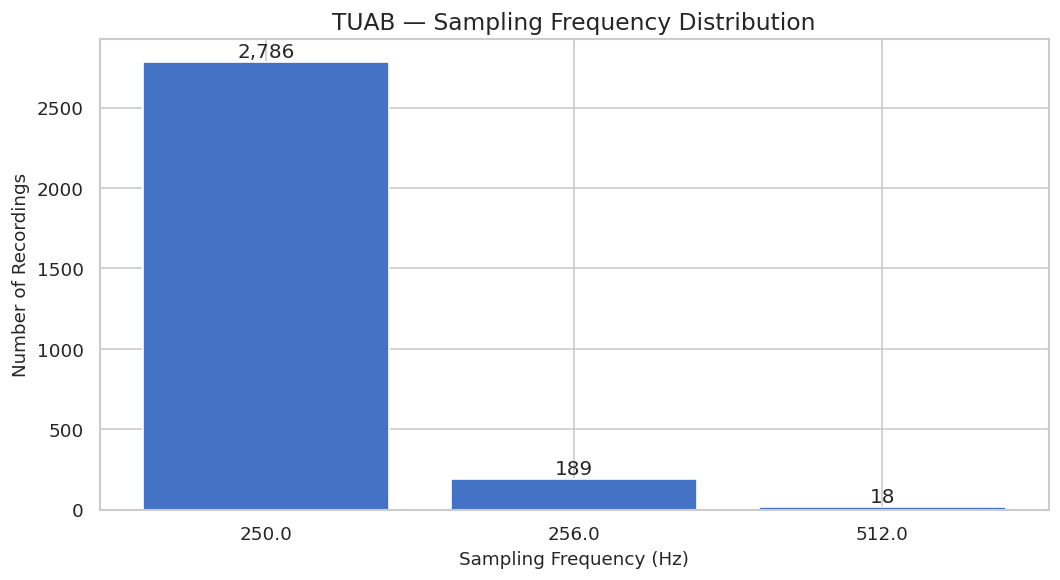

In [9]:
sfreq_counts = (
    meta_df["sfreq"]
    .value_counts()
    .sort_index()
)

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    sfreq_counts.index.astype(str),
    sfreq_counts.values,
    color="#4472C4"
)

for bar, count in zip(bars, sfreq_counts.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 30,
        f"{count:,}",
        ha="center"
    )

ax.set_title("TUAB — Sampling Frequency Distribution")
ax.set_xlabel("Sampling Frequency (Hz)")
ax.set_ylabel("Number of Recordings")

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/sampling_frequency.png")
plt.show()

# Channel count distribution

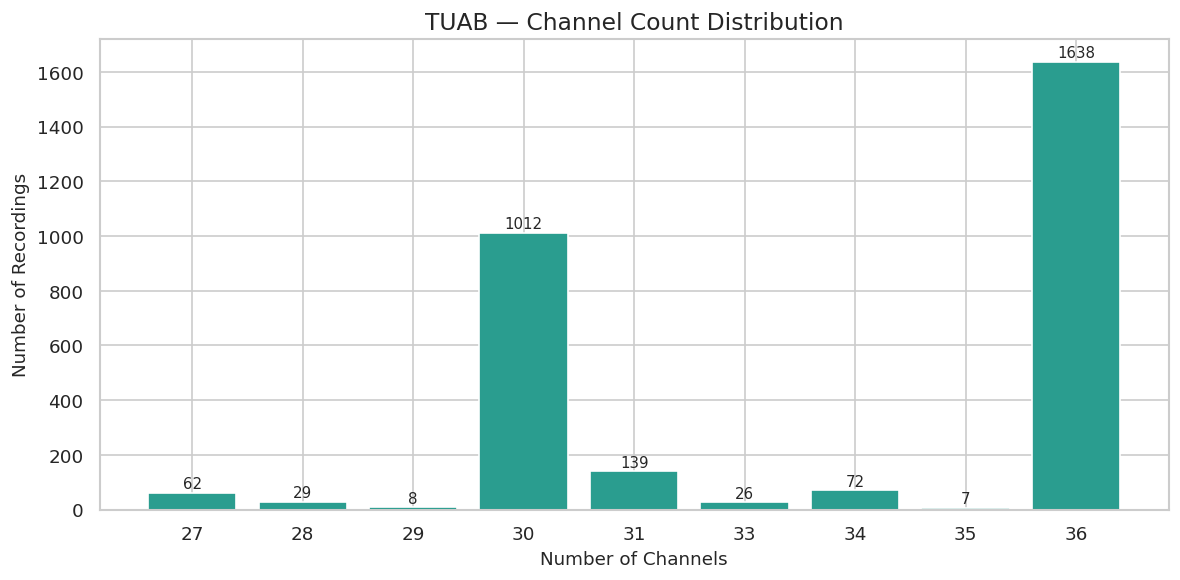

In [10]:
channel_counts = (
    meta_df["n_channels"]
    .value_counts()
    .sort_index()
)

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(
    channel_counts.index.astype(str),
    channel_counts.values,
    color="#2A9D8F"
)

for bar, count in zip(bars, channel_counts.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 15,
        str(count),
        ha="center",
        fontsize=9
    )

ax.set_title("TUAB — Channel Count Distribution")
ax.set_xlabel("Number of Channels")
ax.set_ylabel("Number of Recordings")

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/channel_distribution.png")
plt.show()

# Recording duration distribution

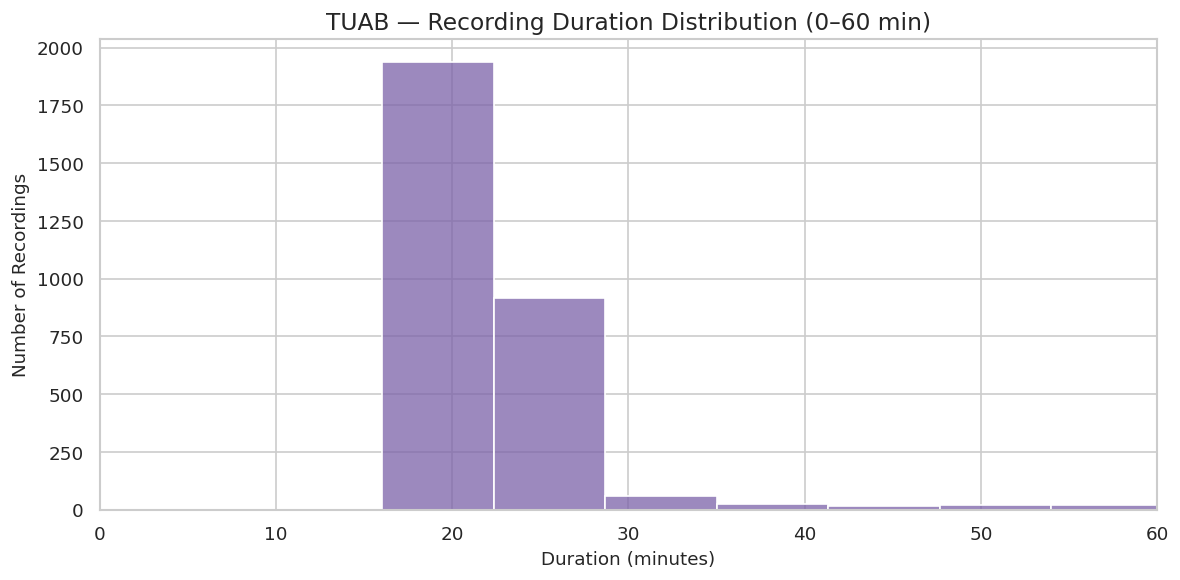

In [12]:
fig, ax = plt.subplots(figsize=(10, 5))

sns.histplot(
    durations_min,
    bins=50,
    color="#7B61A8",
    ax=ax
)

ax.set_xlim(0, 60)
ax.set_title("TUAB — Recording Duration Distribution (0–60 min)")
ax.set_xlabel("Duration (minutes)")
ax.set_ylabel("Number of Recordings")

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/recording_duration_zoom.png")
plt.show()

# Normal versus abnormal class distribution

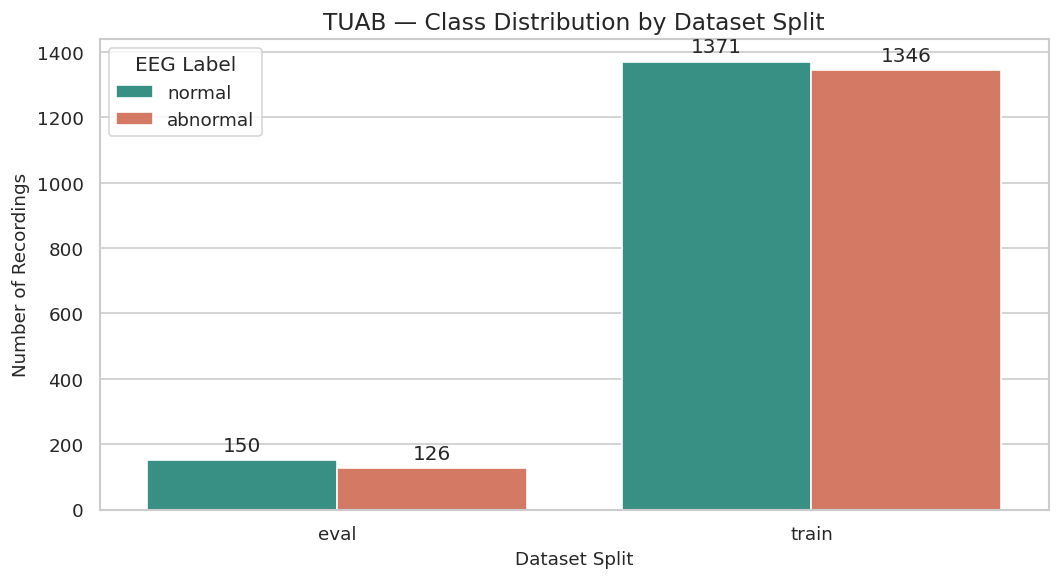

In [13]:
counts = (
    df.groupby(["split", "label"])
    .size()
    .reset_index(name="count")
)

fig, ax = plt.subplots(figsize=(9, 5))

sns.barplot(
    data=counts,
    x="split",
    y="count",
    hue="label",
    hue_order=["normal", "abnormal"],
    palette=["#2A9D8F", "#E76F51"],
    ax=ax
)

for container in ax.containers:
    ax.bar_label(container, padding=3)

ax.set_title("TUAB — Class Distribution by Dataset Split")
ax.set_xlabel("Dataset Split")
ax.set_ylabel("Number of Recordings")
ax.legend(title="EEG Label")

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/class_distribution.png")
plt.show()

# EEG channel availability

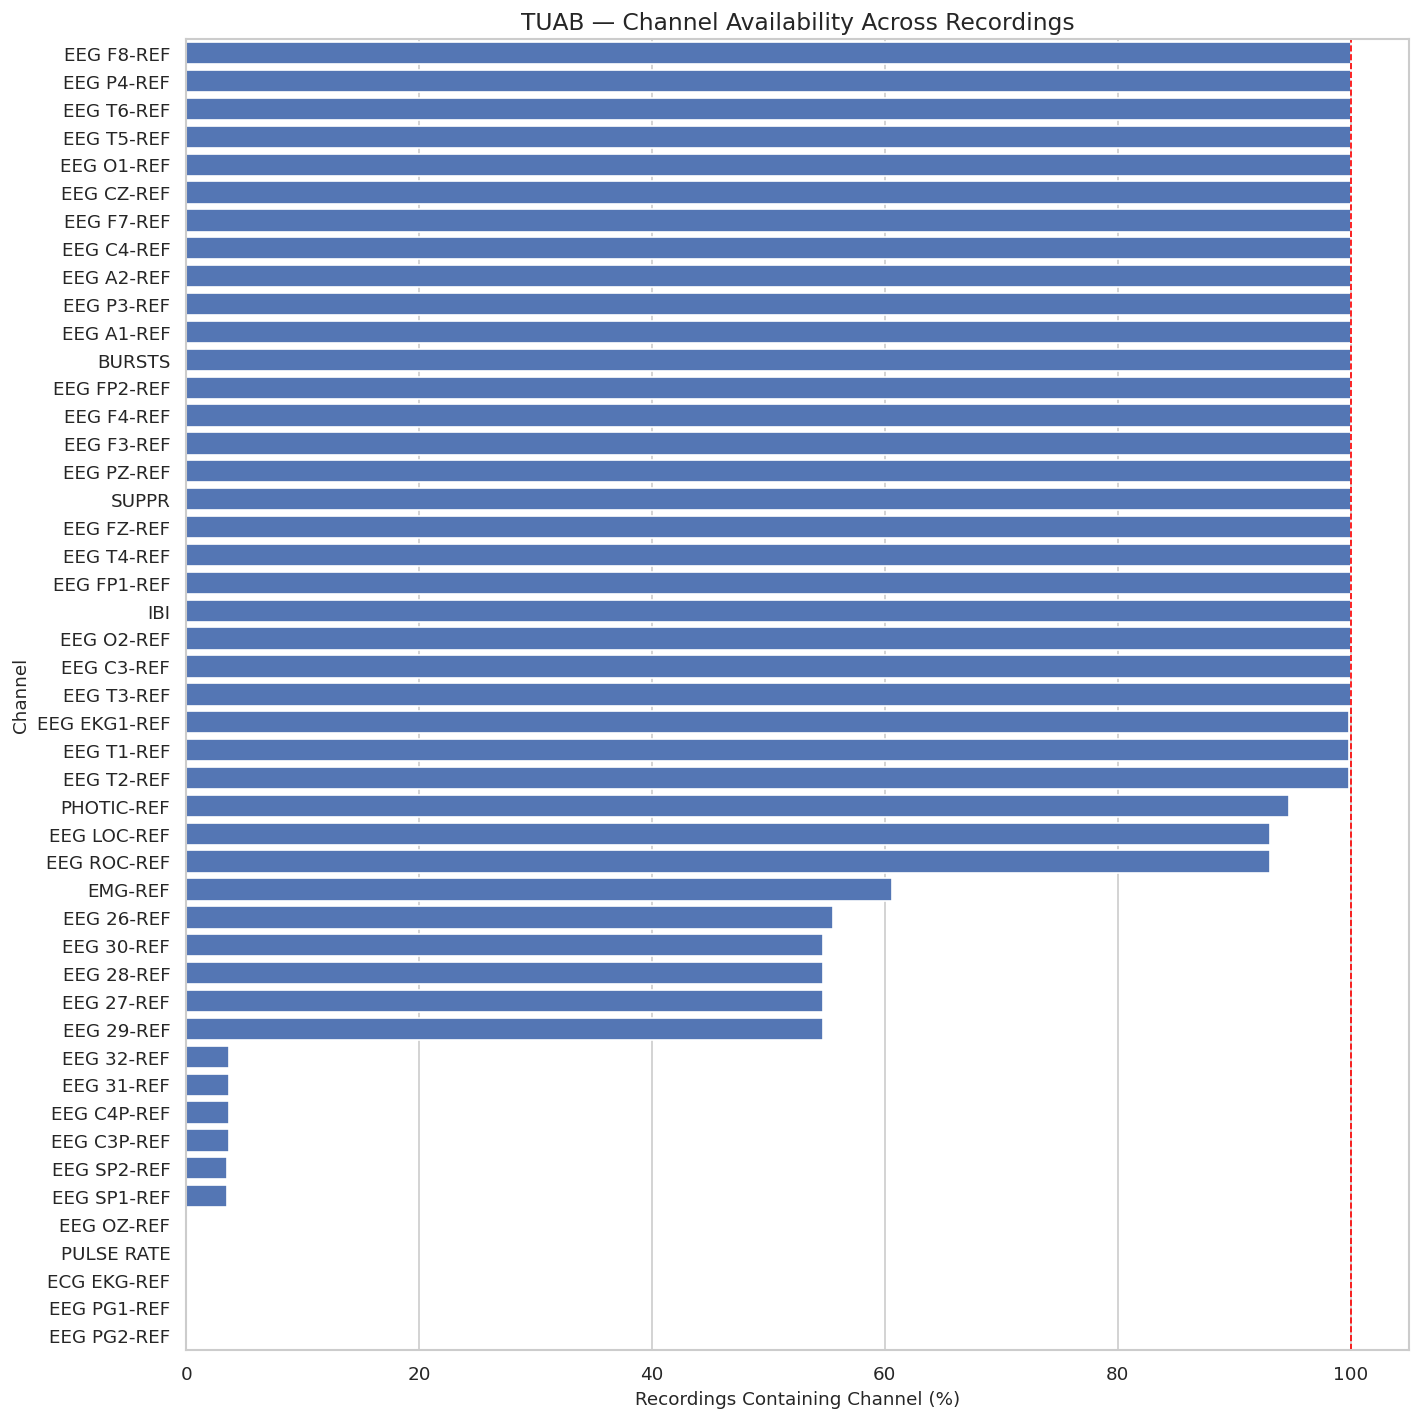


Channels available in every recording:
['EEG F8-REF', 'EEG P4-REF', 'EEG T6-REF', 'EEG T5-REF', 'EEG O1-REF', 'EEG CZ-REF', 'EEG F7-REF', 'EEG C4-REF', 'EEG A2-REF', 'EEG P3-REF', 'EEG A1-REF', 'BURSTS', 'EEG FP2-REF', 'EEG F4-REF', 'EEG F3-REF', 'EEG PZ-REF', 'SUPPR', 'EEG FZ-REF', 'EEG T4-REF', 'EEG FP1-REF', 'IBI', 'EEG O2-REF', 'EEG C3-REF', 'EEG T3-REF']


In [14]:
from collections import Counter

channel_counter = Counter()

for channels in meta_df["channels"]:
    channel_counter.update(set(channels))

channel_df = pd.DataFrame(
    channel_counter.items(),
    columns=["channel", "recordings"]
)

channel_df["availability_pct"] = (
    channel_df["recordings"] / len(meta_df) * 100
)

channel_df = channel_df.sort_values(
    "availability_pct",
    ascending=False
)

fig, ax = plt.subplots(figsize=(12, 12))

sns.barplot(
    data=channel_df,
    x="availability_pct",
    y="channel",
    color="#4472C4",
    ax=ax
)

ax.axvline(
    100,
    color="red",
    linestyle="--",
    linewidth=1
)

ax.set_title("TUAB — Channel Availability Across Recordings")
ax.set_xlabel("Recordings Containing Channel (%)")
ax.set_ylabel("Channel")
ax.set_xlim(0, 105)

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/channel_availability.png")
plt.show()

print("\nChannels available in every recording:")
print(
    channel_df.loc[
        channel_df["availability_pct"] == 100,
        "channel"
    ].tolist()
)

# inspect actual EEG signals


NORMAL
File: /kaggle/input/datasets/mouadelbaz/tuh-normal-abnormal-dataset/TUAB/edf/train/normal/01_tcp_ar/aaaaaaav_s004_t000.edf
Sampling frequency: 250.0
Amplitude range (µV): -39.05896943571295 79.80690435499109

ABNORMAL
File: /kaggle/input/datasets/mouadelbaz/tuh-normal-abnormal-dataset/TUAB/edf/train/abnormal/01_tcp_ar/aaaaaaaq_s004_t000.edf
Sampling frequency: 250.0
Amplitude range (µV): -45.62024359874283 37.99785503707978


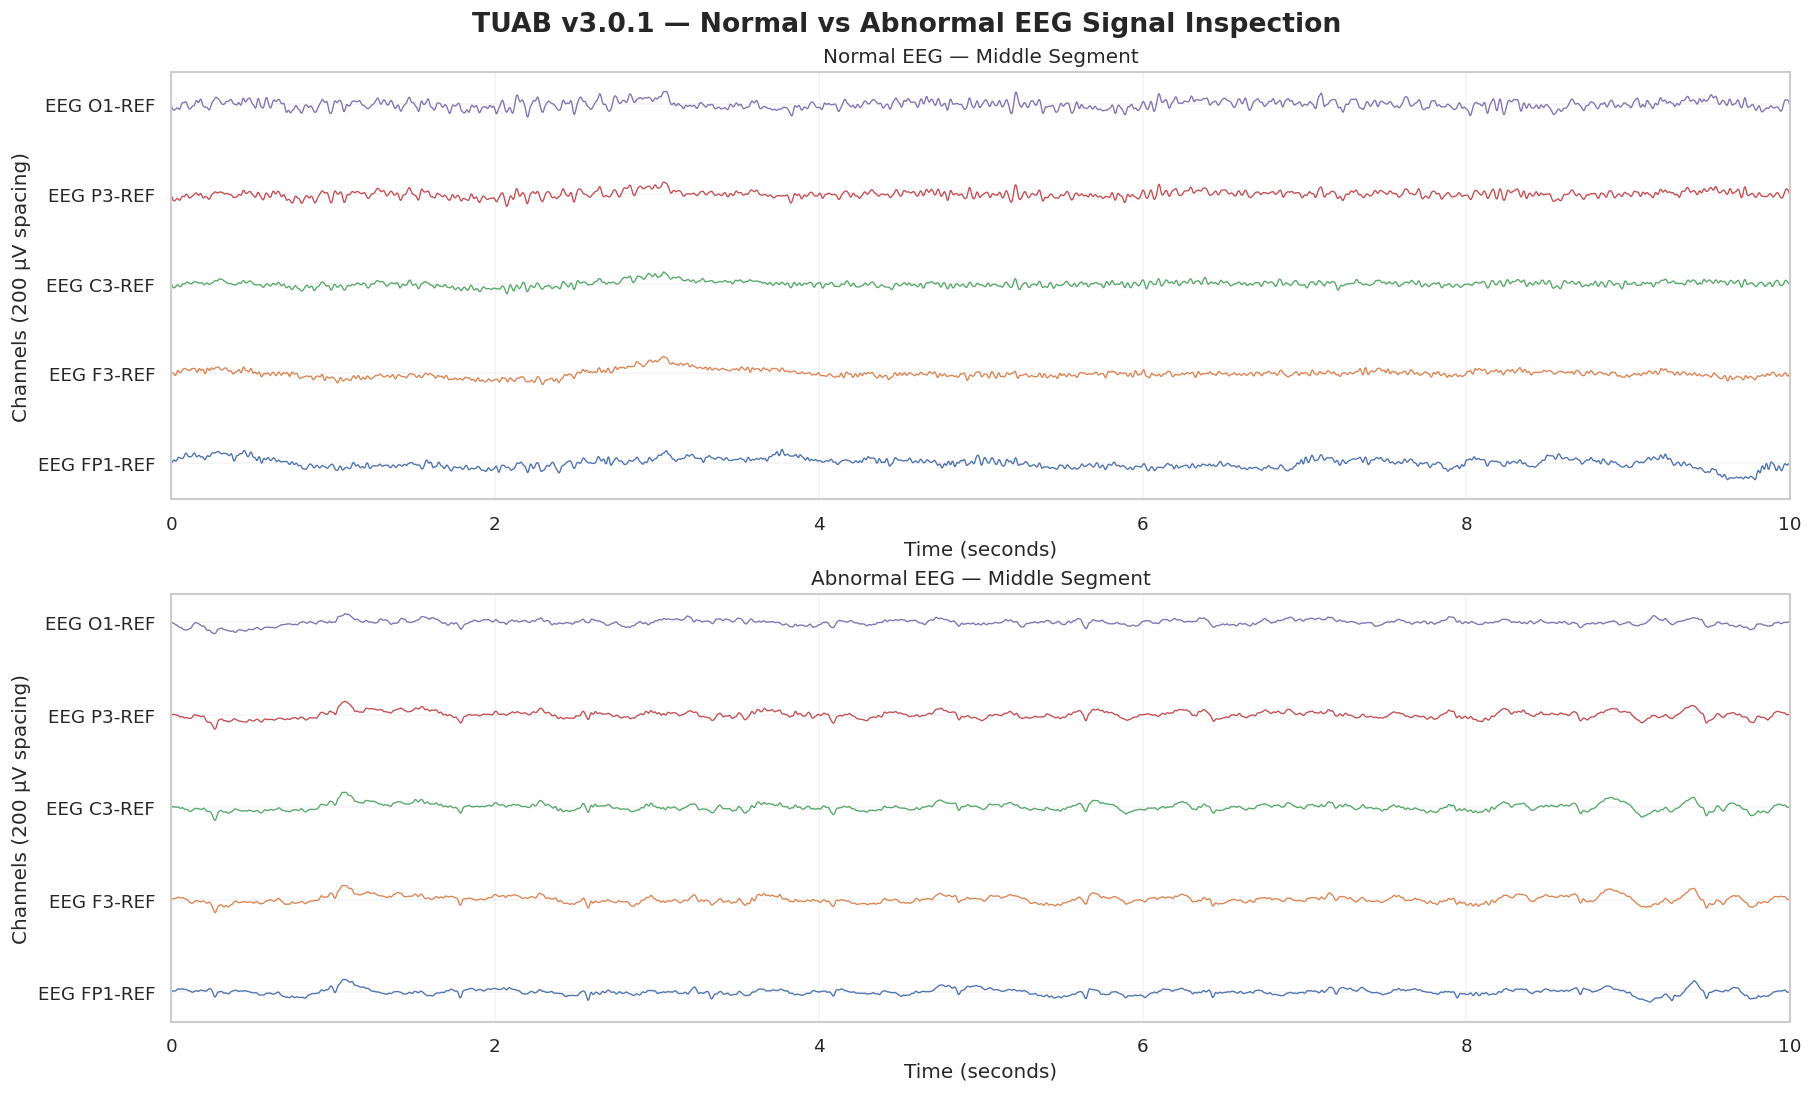


Figure saved successfully: True
Location: /kaggle/working/figures/eeg_signal_inspection.png


In [28]:
import mne
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Output directory
FIGURES_DIR = Path("/kaggle/working/figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

SELECTED_CHANNELS = [
    "EEG FP1-REF",
    "EEG F3-REF",
    "EEG C3-REF",
    "EEG P3-REF",
    "EEG O1-REF",
]


def plot_eeg_segment(label, ax, duration=10):

    path = df.loc[
        (df["split"] == "train") &
        (df["label"] == label),
        "filepath"
    ].iloc[0]

    raw = mne.io.read_raw_edf(
        path,
        preload=False,
        verbose="ERROR"
    )

    try:
        sfreq = raw.info["sfreq"]

        # Select a 10-second segment centered
        # around the middle of the recording
        segment_samples = int(duration * sfreq)

        start = max(
            0,
            (raw.n_times - segment_samples) // 2
        )

        stop = min(
            raw.n_times,
            start + segment_samples
        )

        data = raw.get_data(
            picks=SELECTED_CHANNELS,
            start=start,
            stop=stop
        )

        # Convert volts to microvolts
        data_uv = data * 1e6

        print(f"\n{label.upper()}")
        print("File:", path)
        print("Sampling frequency:", sfreq)
        print(
            "Amplitude range (µV):",
            np.min(data_uv),
            np.max(data_uv)
        )

        # Filter for visualization only
        filtered = mne.filter.filter_data(
            data,
            sfreq=sfreq,
            l_freq=0.5,
            h_freq=40,
            verbose=False
        ) * 1e6

        times = np.arange(
            filtered.shape[1]
        ) / sfreq

        # Consistent vertical spacing
        spacing = 200

        for i, channel in enumerate(SELECTED_CHANNELS):
            ax.plot(
                times,
                filtered[i] + i * spacing,
                linewidth=0.8
            )

        ax.set_yticks(
            np.arange(len(SELECTED_CHANNELS)) * spacing
        )

        ax.set_yticklabels(SELECTED_CHANNELS)

        ax.set_xlabel("Time (seconds)")
        ax.set_ylabel("Channels (200 µV spacing)")
        ax.set_title(
            f"{label.capitalize()} EEG — Middle Segment"
        )
        ax.grid(alpha=0.2)
        ax.set_xlim(0, duration)

    finally:
        raw.close()


# Create figure
fig, axes = plt.subplots(
    2, 1,
    figsize=(15, 9),
    constrained_layout=True
)

plot_eeg_segment("normal", axes[0])
plot_eeg_segment("abnormal", axes[1])

fig.suptitle(
    "TUAB v3.0.1 — Normal vs Abnormal EEG Signal Inspection",
    fontsize=16,
    fontweight="bold"
)

# Save figure BEFORE displaying
save_path = FIGURES_DIR / "eeg_signal_inspection.png"

fig.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# Verify saved image
print("\nFigure saved successfully:", save_path.exists())
print("Location:", save_path)

# Quantitative EEG Signal-Quality Assessment

In [17]:
### Configuration
import numpy as np
import pandas as pd
import mne
from scipy.signal import welch
from tqdm.auto import tqdm
from pathlib import Path

EEG_CHANNELS = [
    "EEG FP1-REF", "EEG FP2-REF",
    "EEG F3-REF", "EEG F4-REF",
    "EEG C3-REF", "EEG C4-REF",
    "EEG P3-REF", "EEG P4-REF",
    "EEG O1-REF", "EEG O2-REF",
    "EEG F7-REF", "EEG F8-REF",
    "EEG T3-REF", "EEG T4-REF",
    "EEG T5-REF", "EEG T6-REF",
    "EEG FZ-REF", "EEG CZ-REF",
    "EEG PZ-REF"
]

QC_CONFIG = {
    "segment_duration_sec": 10,
    "segment_positions": [0.25, 0.50, 0.75],
    "flatline_diff_uv": 0.5,
    "extreme_amplitude_uv": 500,
    "random_seed": 42
}

OUTPUT_DIR = Path("/kaggle/working")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Channels:", len(EEG_CHANNELS))
print("Segments per recording:",
      len(QC_CONFIG["segment_positions"]))

Channels: 19
Segments per recording: 3


In [18]:
### Quality metrics
def calculate_qc_metrics(signal_v, sfreq):
    """
    signal_v: 1D EEG signal in volts
    sfreq: sampling frequency in Hz
    """

    x = np.asarray(signal_v, dtype=np.float64) * 1e6

    if not np.all(np.isfinite(x)):
        return None

    # Amplitude statistics
    ptp_uv = np.ptp(x)
    rms_uv = np.sqrt(np.mean(x ** 2))
    std_uv = np.std(x)

    # Flatline-like behavior based on adjacent samples
    differences = np.abs(np.diff(x))

    flatline_pct = (
        np.mean(
            differences < QC_CONFIG["flatline_diff_uv"]
        ) * 100
    )

    # Extreme amplitude relative to segment median
    centered = x - np.median(x)

    extreme_pct = (
        np.mean(
            np.abs(centered) >
            QC_CONFIG["extreme_amplitude_uv"]
        ) * 100
    )

    # Welch power spectral density
    freqs, psd = welch(
        x,
        fs=sfreq,
        nperseg=min(len(x), int(4 * sfreq))
    )

    def line_noise_ratio(target_hz):
        # Target: ±1 Hz
        signal_band = (
            (freqs >= target_hz - 1) &
            (freqs <= target_hz + 1)
        )

        # Nearby reference frequencies
        reference_band = (
            ((freqs >= target_hz - 5) &
             (freqs < target_hz - 2)) |
            ((freqs > target_hz + 2) &
             (freqs <= target_hz + 5))
        )

        if not signal_band.any() or not reference_band.any():
            return np.nan

        target_power = np.mean(psd[signal_band])
        reference_power = np.mean(psd[reference_band])

        return 10 * np.log10(
            (target_power + 1e-12) /
            (reference_power + 1e-12)
        )

    return {
        "ptp_uv": ptp_uv,
        "rms_uv": rms_uv,
        "std_uv": std_uv,
        "flatline_pct": flatline_pct,
        "extreme_pct": extreme_pct,
        "line_noise_50_db": line_noise_ratio(50),
        "line_noise_60_db": line_noise_ratio(60)
    }

In [19]:
### Run the quality audit
qc_records = []
qc_errors = []

for i, row in enumerate(
    tqdm(df.itertuples(index=False), total=len(df))
):
    path = row.filepath

    try:
        raw = mne.io.read_raw_edf(
            path,
            preload=False,
            verbose="ERROR"
        )

        sfreq = raw.info["sfreq"]
        duration = raw.n_times / sfreq

        for position in QC_CONFIG["segment_positions"]:

            start_sec = (
                position *
                (duration - QC_CONFIG["segment_duration_sec"])
            )

            start = int(start_sec * sfreq)
            stop = start + int(
                QC_CONFIG["segment_duration_sec"] * sfreq
            )

            data = raw.get_data(
                picks=EEG_CHANNELS,
                start=start,
                stop=stop
            )

            for channel, signal in zip(
                EEG_CHANNELS, data
            ):
                metrics = calculate_qc_metrics(
                    signal, sfreq
                )

                if metrics is None:
                    qc_errors.append({
                        "filepath": path,
                        "channel": channel,
                        "error": "Non-finite values"
                    })
                    continue

                qc_records.append({
                    "filepath": path,
                    "split": row.split,
                    "label": row.label,
                    "subject_id": row.subject_id,
                    "channel": channel,
                    "segment_position": position,
                    "sfreq": sfreq,
                    **metrics
                })

        raw.close()

    except Exception as e:
        qc_errors.append({
            "filepath": path,
            "error": str(e)
        })

    if (i + 1) % 100 == 0:
        pd.DataFrame(qc_records).to_csv(
            OUTPUT_DIR / "tuab_qc_partial.csv",
            index=False
        )

qc_df = pd.DataFrame(qc_records)

qc_df.to_csv(
    OUTPUT_DIR / "tuab_qc_metrics.csv",
    index=False
)

pd.DataFrame(qc_errors).to_csv(
    OUTPUT_DIR / "tuab_qc_errors.csv",
    index=False
)

print("QC observations:", len(qc_df))
print("QC errors:", len(qc_errors))
print("Unique recordings audited:",
      qc_df["filepath"].nunique())

  0%|          | 0/2993 [00:00<?, ?it/s]

QC observations: 170601
QC errors: 0
Unique recordings audited: 2993


In [20]:
### Summarize quality metrics
qc_columns = [
    "ptp_uv",
    "rms_uv",
    "std_uv",
    "flatline_pct",
    "extreme_pct",
    "line_noise_50_db",
    "line_noise_60_db"
]

summary = qc_df[qc_columns].describe(
    percentiles=[0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
)

display(summary.T.round(3))

recording_qc = (
    qc_df.groupby(["filepath", "split", "label"])
    .agg(
        median_ptp_uv=("ptp_uv", "median"),
        max_ptp_uv=("ptp_uv", "max"),
        median_rms_uv=("rms_uv", "median"),
        max_flatline_pct=("flatline_pct", "max"),
        max_extreme_pct=("extreme_pct", "max"),
        median_line_noise_50_db=("line_noise_50_db", "median"),
        median_line_noise_60_db=("line_noise_60_db", "median")
    )
    .reset_index()
)

recording_qc.to_csv(
    OUTPUT_DIR / "tuab_recording_qc_summary.csv",
    index=False
)

display(recording_qc.head())

,count,mean,std,min,5%,25%,50%,75%,95%,99%,max
ptp_uv,170601.0,150.432,436.963,3.357,31.586,61.951,92.926,142.364,349.579,915.527,10964.735
rms_uv,170601.0,27.259,121.933,0.495,5.267,9.971,14.935,23.225,58.224,179.295,5012.067
std_uv,170601.0,25.569,117.574,0.488,4.892,9.373,14.006,21.746,54.260,164.718,5005.134
flatline_pct,170601.0,12.690,9.376,0.000,2.401,6.082,10.364,16.647,31.333,45.418,100.000
extreme_pct,170601.0,0.263,4.068,0.000,0.000,0.000,0.000,0.000,0.000,0.400,97.969
line_noise_50_db,170601.0,-0.166,1.397,-13.818,-2.409,-1.033,-0.144,0.720,2.014,3.119,11.296
line_noise_60_db,170601.0,5.889,8.304,-11.626,-1.383,0.520,2.652,8.502,23.940,35.495,70.320


,filepath,split,label,median_ptp_uv,max_ptp_uv,median_rms_uv,max_flatline_pct,max_extreme_pct,median_line_noise_50_db,median_line_noise_60_db
0,/kaggle/input/datasets/mouadelbaz/tuh-normal-a...,eval,abnormal,110.931310,221.710032,17.701484,48.259304,0.0,-0.086758,13.893085
1,/kaggle/input/datasets/mouadelbaz/tuh-normal-a...,eval,abnormal,74.005069,122.833156,12.514450,29.771909,0.0,0.029922,3.206636
2,/kaggle/input/datasets/mouadelbaz/tuh-normal-a...,eval,abnormal,95.367357,315.704099,14.345543,40.976391,0.0,0.184915,1.691910
3,/kaggle/input/datasets/mouadelbaz/tuh-normal-a...,eval,abnormal,102.538982,229.034245,16.307920,38.575430,0.0,-0.505718,0.997794
4,/kaggle/input/datasets/mouadelbaz/tuh-normal-a...,eval,abnormal,130.004781,256.347456,18.593850,19.047619,0.0,-0.260908,2.566989


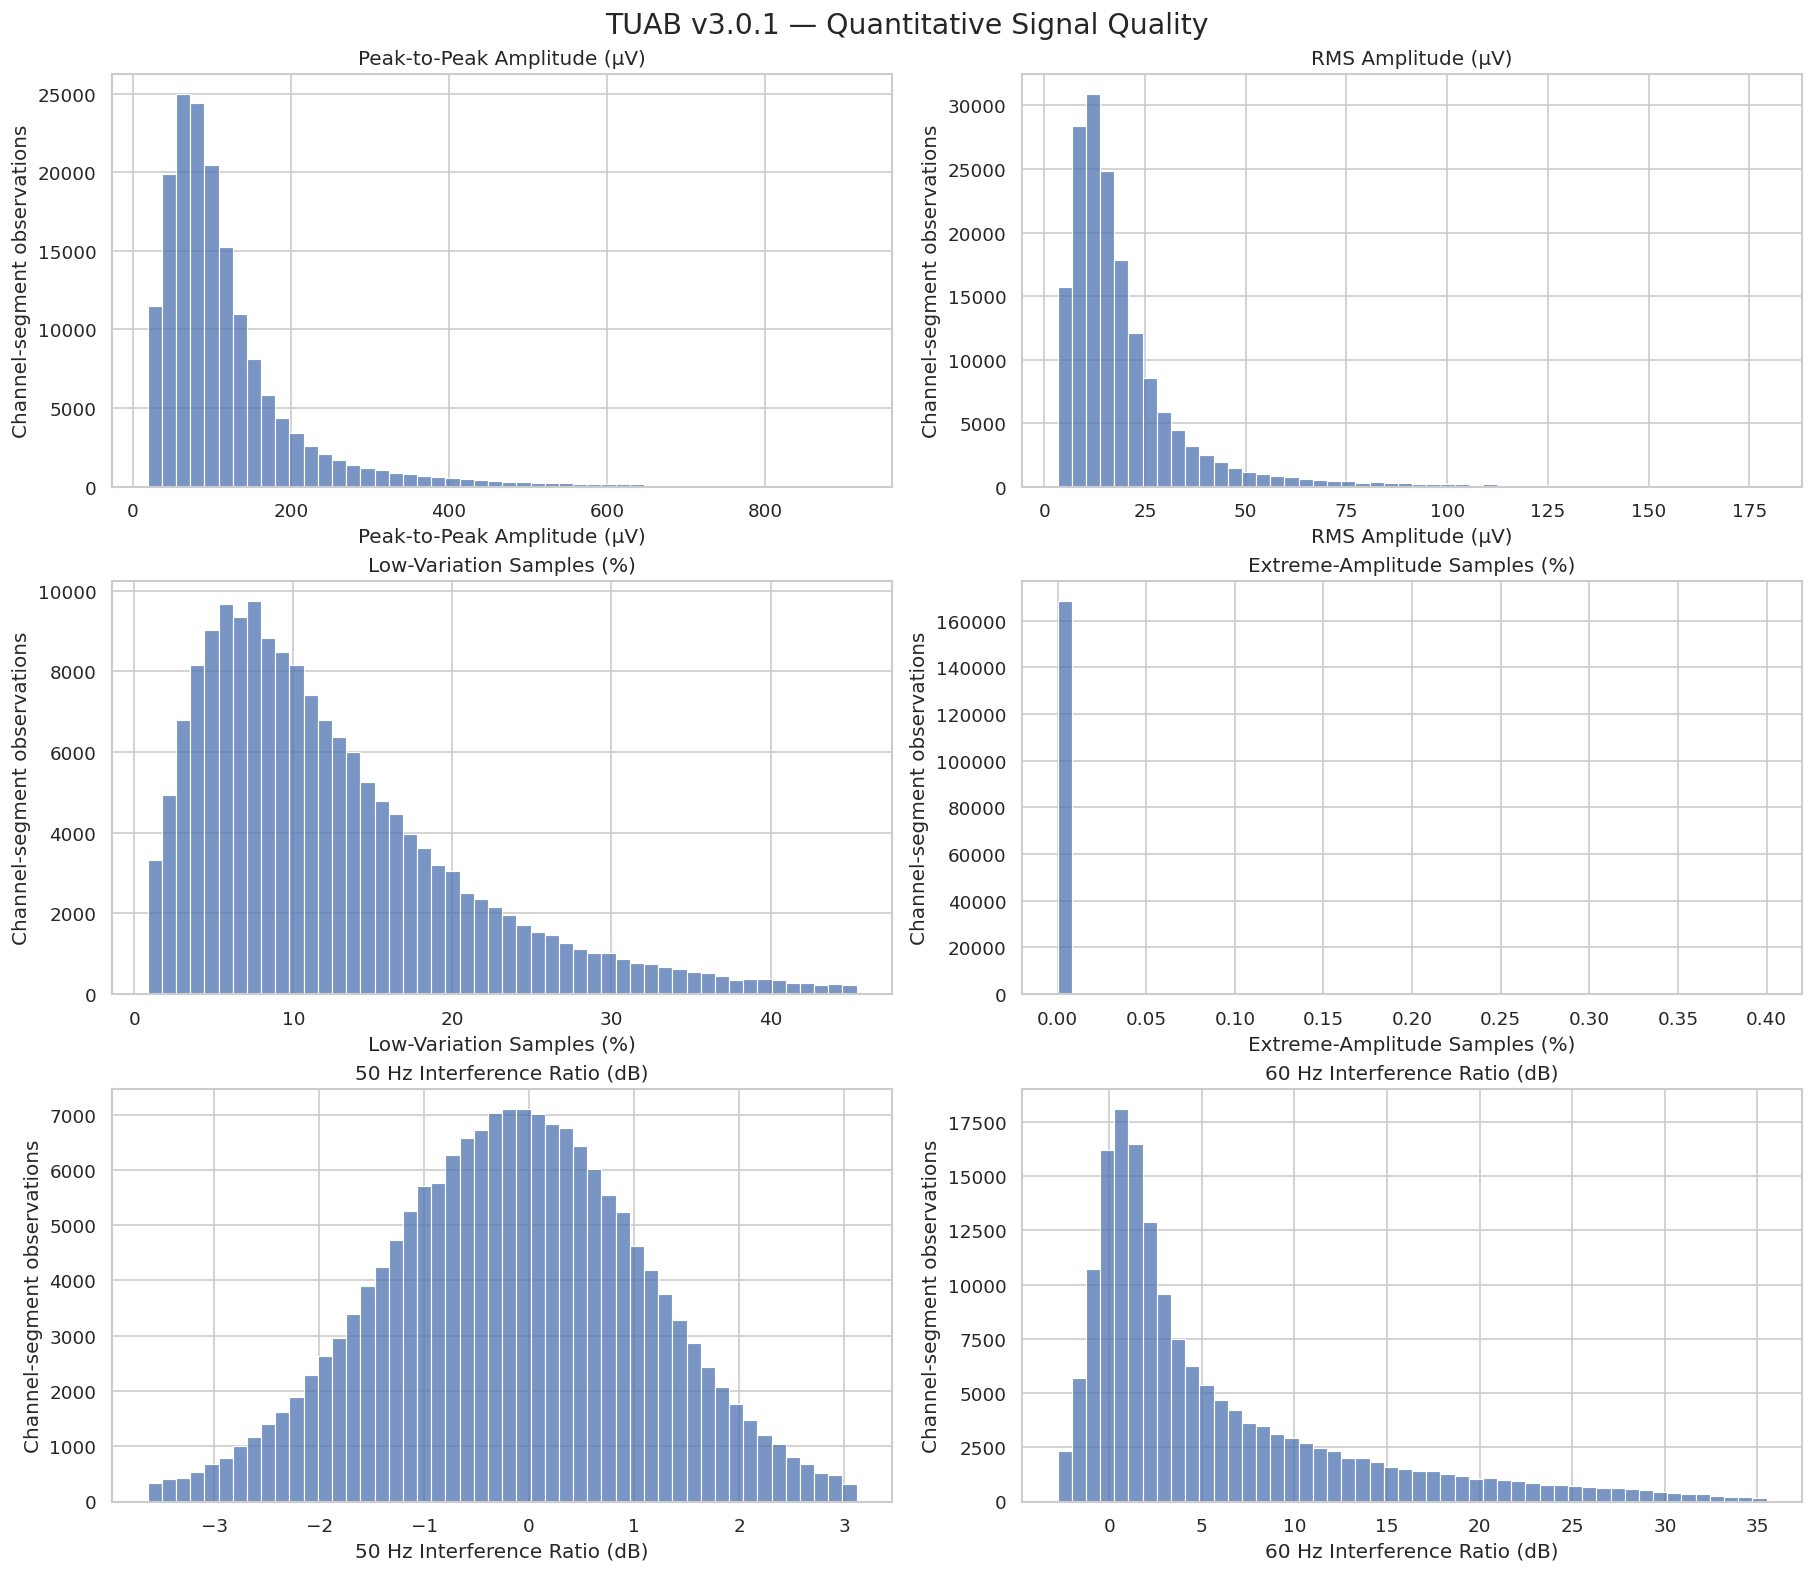

In [21]:
### Visualize the quality metrics
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

metrics_to_plot = [
    ("ptp_uv", "Peak-to-Peak Amplitude (µV)"),
    ("rms_uv", "RMS Amplitude (µV)"),
    ("flatline_pct", "Low-Variation Samples (%)"),
    ("extreme_pct", "Extreme-Amplitude Samples (%)"),
    ("line_noise_50_db", "50 Hz Interference Ratio (dB)"),
    ("line_noise_60_db", "60 Hz Interference Ratio (dB)")
]

fig, axes = plt.subplots(
    3, 2,
    figsize=(15, 13),
    constrained_layout=True
)

for ax, (metric, title) in zip(
    axes.flat, metrics_to_plot
):
    values = qc_df[metric].replace(
        [np.inf, -np.inf], np.nan
    ).dropna()

    # Plot up to the 99th percentile for readability
    upper = values.quantile(0.99)
    lower = values.quantile(0.01)

    sns.histplot(
        values[(values >= lower) & (values <= upper)],
        bins=50,
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel(title)
    ax.set_ylabel("Channel-segment observations")

fig.suptitle(
    "TUAB v3.0.1 — Quantitative Signal Quality",
    fontsize=17
)

plt.savefig(
    OUTPUT_DIR / "tuab_signal_quality.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

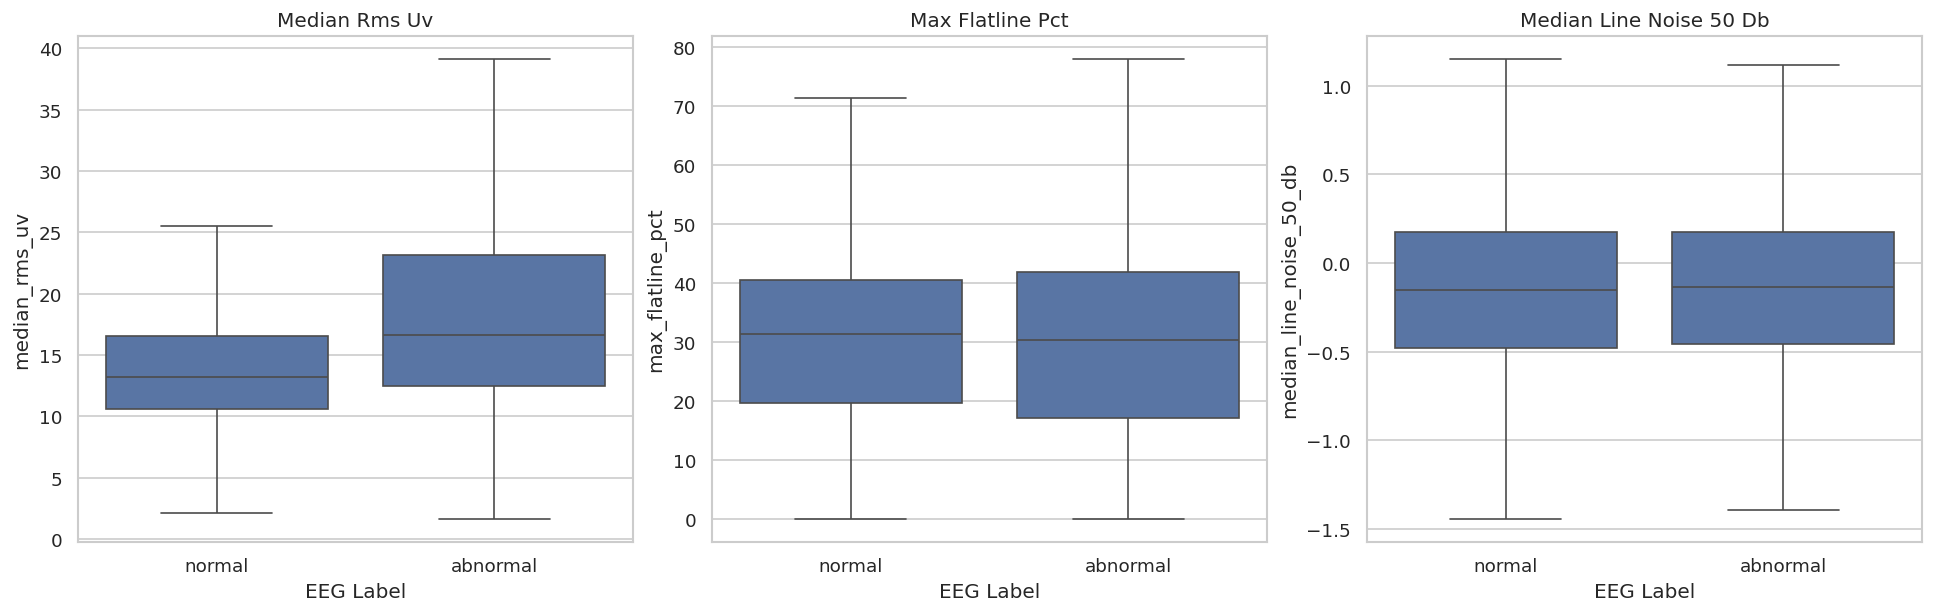

In [22]:
### Compare quality metrics by label
fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 5),
    constrained_layout=True
)

comparison_metrics = [
    "median_rms_uv",
    "max_flatline_pct",
    "median_line_noise_50_db"
]

for ax, metric in zip(axes, comparison_metrics):

    sns.boxplot(
        data=recording_qc,
        x="label",
        y=metric,
        order=["normal", "abnormal"],
        showfliers=False,
        ax=ax
    )

    ax.set_title(metric.replace("_", " ").title())
    ax.set_xlabel("EEG Label")

plt.savefig(
    OUTPUT_DIR / "tuab_quality_by_label.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Organize research figures

In [29]:
from pathlib import Path
import shutil

FIGURES_DIR = Path("/kaggle/working/figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

figure_names = [
    "sampling_frequency",
    "channel_distribution",
    "recording_duration",
    "recording_duration_zoom",
    "class_distribution",
    "channel_availability",
    "eeg_signal_inspection",
    "tuab_signal_quality",
    "tuab_quality_by_label"
]

for name in figure_names:
    source = Path(f"/kaggle/working/{name}.png")

    if source.exists():
        shutil.copy2(
            source,
            FIGURES_DIR / source.name
        )

print("Saved figures:")
for file in sorted(FIGURES_DIR.glob("*.png")):
    print(file.name)

Saved figures:
channel_availability.png
channel_distribution.png
class_distribution.png
eeg_signal_inspection.png
recording_duration.png
recording_duration_zoom.png
sampling_frequency.png
tuab_quality_by_label.png
tuab_signal_quality.png


# Download all figures as ZIP

In [30]:
import shutil

zip_path = shutil.make_archive(
    "/kaggle/working/TUAB_Data_Understanding_Figures",
    "zip",
    root_dir="/kaggle/working/figures"
)

print("ZIP created:", zip_path)

ZIP created: /kaggle/working/TUAB_Data_Understanding_Figures.zip
